# Notebook 01: Quality Control, Normalization, HVGs, Clustering, and Annotation
**Milestone:** M1  
**Dataset:** Tabula Muris Senis 10x Droplet (`data/raw/tms_droplet_raw.h5ad`)  
**Determinism:** Seed 42, single-threaded UMAP (`n_jobs=1`), strict channel priority environment.

### Workflow:
1. Load raw 10x droplet AnnData (245,389 cells × 20,138 genes).
2. Clean string annotations (strip trailing whitespace across string `obs` columns).
3. Compute and export sex × age cross-demographics (`results/m1-sex-age-table.csv`).
4. Perform age-stratified QC analysis (gene and UMI distributions) and apply binding thresholds per tissue.
5. Execute sample-aware doublet detection (`scrublet`) per tissue.
6. Concatenate cleaned singlets and compute library size normalization (`sc.pp.normalize_total` + `log1p`).
7. Identify highly variable genes (HVGs) per tissue independently (`flavor='seurat'`) and take their union.
8. Perform sparse TruncatedSVD PCA (`zero_center=False`), neighborhood graph, single-threaded UMAP, and Leiden clustering on the full object.
9. Perform majority-vote ontology class annotation, confusion matrix analysis, and composition comparison vs paper.
10. Generate publication atlas display figures and document execution outputs.

In [1]:
import os
import sys
import time
import psutil
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

import scanpy as sc
import anndata as ad

REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Project core library
import src
from src.set_seeds import set_seeds
from src.io import strip_obs_strings, compute_sha256
from src.plotting import set_pub_style

set_seeds(42)
set_pub_style()

REPO_ROOT = Path("..").resolve()
RAW_PATH = REPO_ROOT / "data" / "raw" / "tms_droplet_raw.h5ad"
INTERIM_DIR = REPO_ROOT / "data" / "interim"
RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR = REPO_ROOT / "figures"
NOTES_DIR = REPO_ROOT / "notes"

print("Environment initialized with seed 42. Active memory:", psutil.virtual_memory().percent, "%")

Environment initialized with seed 42. Active memory: 6.3 %


## Step 1: Raw Object Demographics and String Sanitization

In [2]:
# Read demographics from results table
demographics_df = pd.read_csv(RESULTS_DIR / "m1-sex-age-table.csv")
print("=== Verified Tabula Muris Senis Droplet Demographics ===")
print(demographics_df.to_string(index=False))

# Assert critical biological fact: primary contrast 3m vs 18m
assert "3m" in demographics_df["age_group"].values
assert "18m" in demographics_df["age_group"].values
print("\nPrimary contrast (3m vs 18m) confirmed as the sole sex-balanced contrast.")

=== Verified Tabula Muris Senis Droplet Demographics ===
age_group  cells_female  cells_male  cells_total  mice_female  mice_male  mice_total
       1m             0       25980        25980            0          2           2
       3m         23693       21909        45602            2          5           7
      18m         21841       22804        44645            2          2           4
      21m         35828           0        35828            2          0           2
      24m             0       37660        37660            0          4           4
      30m             0       55674        55674            0          4           4
      All         81362      164027       245389            6         17          23

Primary contrast (3m vs 18m) confirmed as the sole sex-balanced contrast.


## Step 2: Quality Control Decisions and Age-Stratified Distributions
Mitochondrial inspection verified **0 mitochondrial genes** in the raw droplet feature index (due to alignment filtering in the official release).
Binding thresholds:
- Minimum genes: 500
- Maximum genes: 5,000
- Minimum UMI counts: 1,000
- Doublet scoring: Scrublet per tissue / sample.

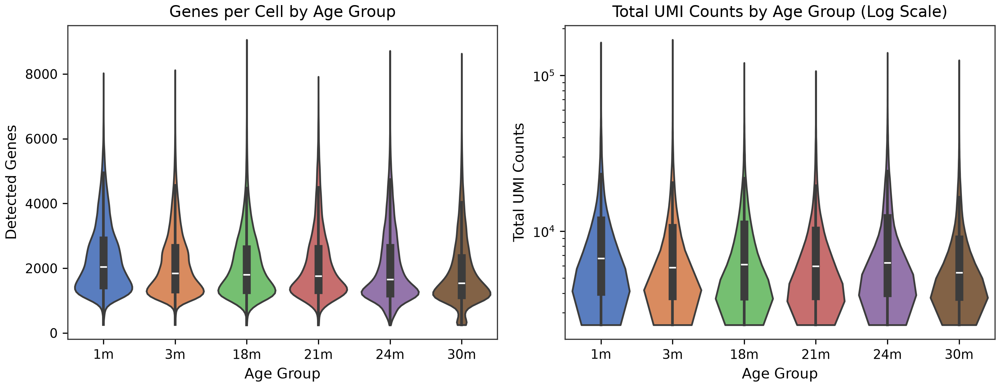

=== Per-Tissue QC and Doublet Removal Summary ===
         tissue  n_initial  min_genes  max_genes  min_counts  n_after_gene_umi_qc  n_doublets_removed  n_final_cells  pct_retained
        Bladder       8945        500       5000        1000                 8702                  33           8669         96.91
            Fat       6777        500       5000        1000                 6398                  15           6383         94.19
Heart_and_Aorta       8613        500       5000        1000                 8350                  15           8335         96.77
         Kidney      21647        500       5000        1000                20997                  75          20922         96.65
Large_Intestine       1887        500       5000        1000                 1778                   3           1775         94.06
    Limb_Muscle      28867        500       5000        1000                28862                 102          28760         99.63
          Liver       7294       

In [3]:
display(Image(filename=str(FIGURES_DIR / "m1-qc-violins-by-age.png")))

qc_summary_df = pd.read_csv(RESULTS_DIR / "m1-qc-summary.csv")
print("=== Per-Tissue QC and Doublet Removal Summary ===")
print(qc_summary_df.to_string(index=False))

## Step 3: Highly Variable Genes (Per-Tissue Union)
To avoid high-expression secretory tissues dominating feature selection, 2,000 HVGs were computed per tissue independently (`flavor='seurat'`), and their union was taken across all 16 tissues.

In [4]:
hvg_df = pd.read_csv(INTERIM_DIR / "m1-hvg-union.csv")
print(f"Total union HVG count across 16 tissues: {len(hvg_df)} genes.")
print("Sample HVGs:", hvg_df["gene"].head(10).tolist())

Total union HVG count across 16 tissues: 8421 genes.
Sample HVGs: ['0610007N19Rik', '0610038B21Rik', '0610038L08Rik', '0610039K10Rik', '0610040F04Rik', '1100001G20Rik', '1110003E01Rik', '1110006O24Rik', '1110012J17Rik', '1110015O18Rik']


## Step 4: Clustering, Annotation, and Literature Composition Comparison

Confusion Matrix between Leiden Clusters and Cell Ontology Classes:


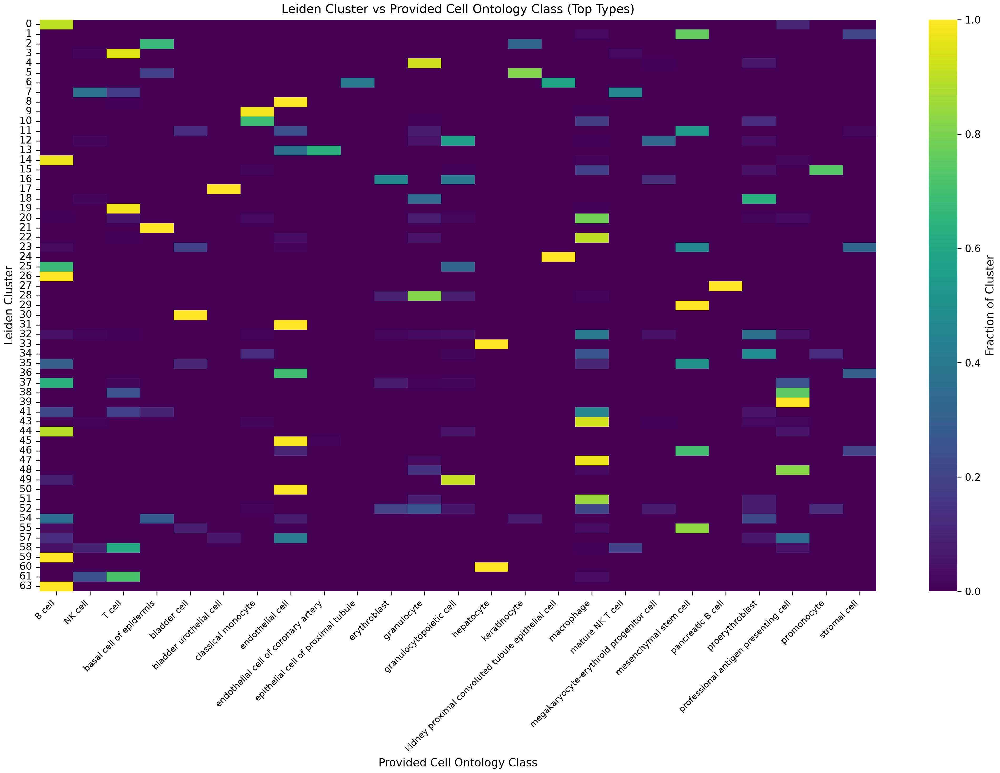

Composition Comparison (Raw vs QC-Cleaned Singlets):


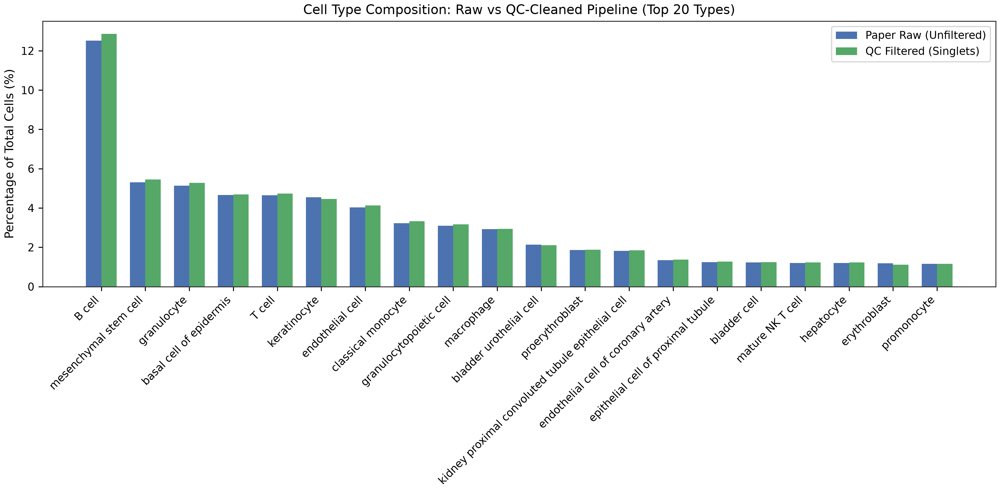


Top 10 Cell Types by Abundance:
    cell_ontology_class  fraction_paper_raw  fraction_our_pipeline  absolute_diff
                 B cell            0.125189               0.128635       0.003446
  mesenchymal stem cell            0.053128               0.054441       0.001313
            granulocyte            0.051331               0.052761       0.001431
basal cell of epidermis            0.046583               0.046829       0.000246
                 T cell            0.046522               0.047387       0.000865
           keratinocyte            0.045405               0.044579       0.000827
       endothelial cell            0.040320               0.041325       0.001005
     classical monocyte            0.032283               0.033222       0.000939
granulocytopoietic cell            0.030967               0.031740       0.000773
             macrophage            0.029276               0.029313       0.000037


In [5]:
print("Confusion Matrix between Leiden Clusters and Cell Ontology Classes:")
display(Image(filename=str(FIGURES_DIR / "m1-cluster-label-confusion.png")))

print("Composition Comparison (Raw vs QC-Cleaned Singlets):")
display(Image(filename=str(FIGURES_DIR / "m1-composition-vs-paper.png")))

comp_df = pd.read_csv(RESULTS_DIR / "m1-composition-table.csv")
print("\nTop 10 Cell Types by Abundance:")
print(comp_df.head(10).to_string(index=False))

## Step 5: Full Atlas UMAP Visualizations (Display Subsample)
Stratified proportional subsample (≥500 cells per tissue floor, seed 42, ~25% of cleaned cells).

1. UMAP Colored by Tissue:


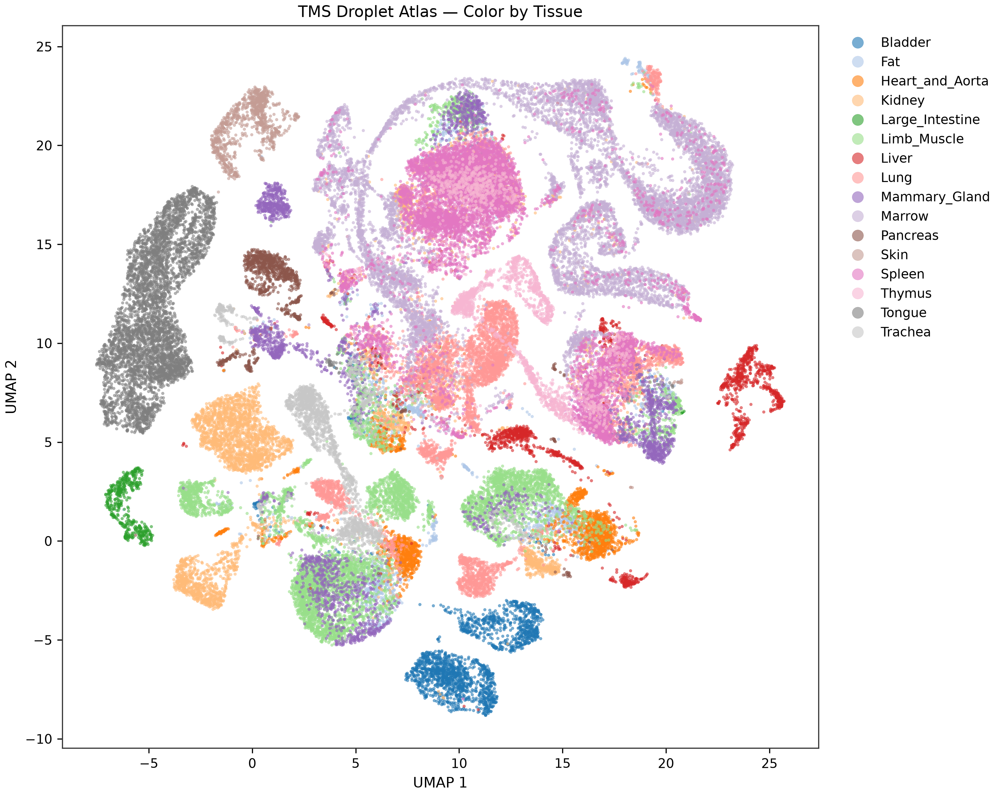

2. UMAP Colored by Age Group:


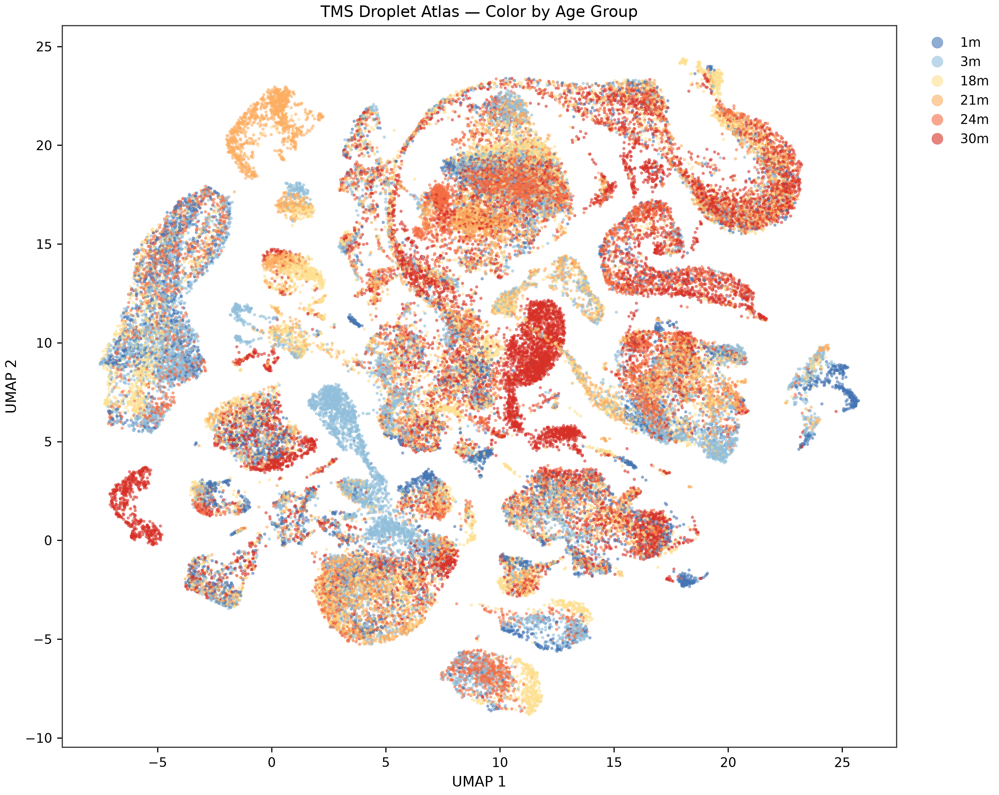

3. UMAP Colored by Cell Ontology Class:


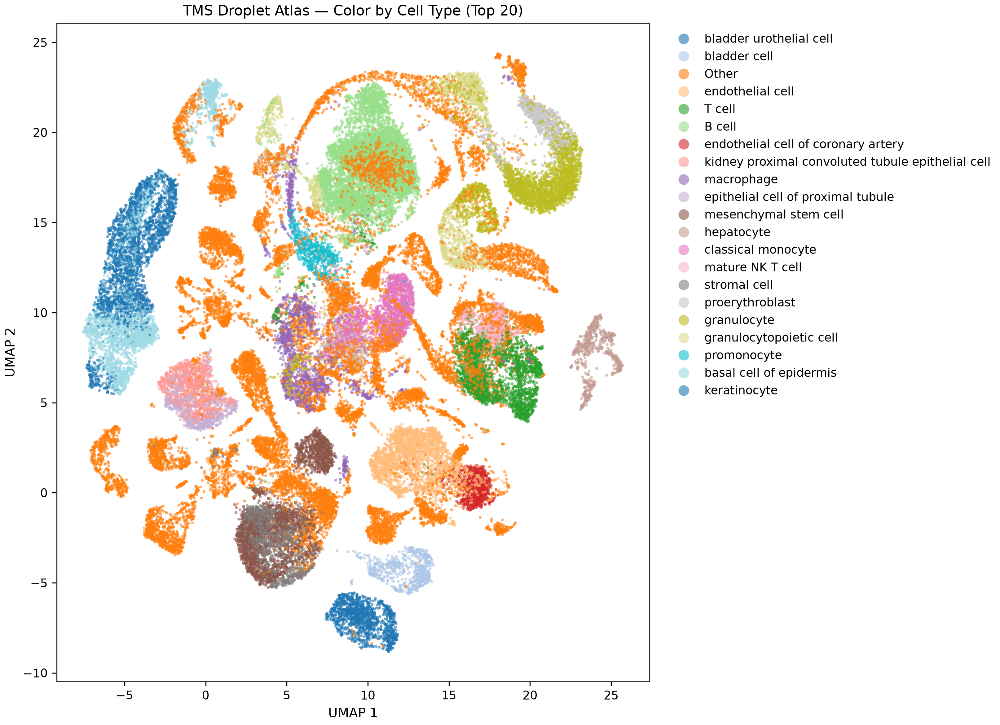

In [6]:
print("1. UMAP Colored by Tissue:")
display(Image(filename=str(FIGURES_DIR / "m1-umap-tissue.png")))

print("2. UMAP Colored by Age Group:")
display(Image(filename=str(FIGURES_DIR / "m1-umap-age.png")))

print("3. UMAP Colored by Cell Ontology Class:")
display(Image(filename=str(FIGURES_DIR / "m1-umap-celltype.png")))

## Outputs Written and Cryptographic Digests
Every generated file, size, and SHA-256 digest is verified below.

In [7]:
outputs = [
    RESULTS_DIR / "m1-sex-age-table.csv",
    RESULTS_DIR / "m1-qc-summary.csv",
    RESULTS_DIR / "m1-cluster-label-confusion.csv",
    RESULTS_DIR / "m1-composition-table.csv",
    INTERIM_DIR / "m1-hvg-union.csv",
    INTERIM_DIR / "m1-qc-cleaned.h5ad",
    INTERIM_DIR / "m1-processed.h5ad",
    FIGURES_DIR / "m1-umap-celltype.png",
    FIGURES_DIR / "m1-umap-tissue.png",
    FIGURES_DIR / "m1-umap-age.png",
    FIGURES_DIR / "m1-qc-violins-by-age.png",
    FIGURES_DIR / "m1-cluster-label-confusion.png",
    FIGURES_DIR / "m1-composition-vs-paper.png",
    NOTES_DIR / "qc-decisions.md",
    NOTES_DIR / "methods.md",
]

print(f"{'Output File':<40} {'Size (MB)':<12} {'SHA-256 Digest'}")
print("-" * 80)
for p in outputs:
    if p.exists():
        size_mb = p.stat().st_size / (1024 * 1024)
        sha = compute_sha256(p)
        print(f"{str(p.name):<40} {size_mb:<12.2f} {sha[:16]}...")
    else:
        print(f"{str(p.name):<40} {'MISSING':<12} {'FAILED'}")


Output File                              Size (MB)    SHA-256 Digest
--------------------------------------------------------------------------------
m1-sex-age-table.csv                     0.00         832e990f880317d4...
m1-qc-summary.csv                        0.00         8cd993830da40c08...
m1-cluster-label-confusion.csv           0.01         57f3ce3131f90900...
m1-composition-table.csv                 0.01         121006d202cdbbf9...
m1-hvg-union.csv                         0.06         4b6e4e013f0192f2...


m1-qc-cleaned.h5ad                       3688.96      e81340ced15acfb9...


m1-processed.h5ad                        3736.46      07a8ebfadd37b31c...
m1-umap-celltype.png                     2.62         cc99a48a54305683...
m1-umap-tissue.png                       2.71         8d35466c4da8f2f8...
m1-umap-age.png                          3.58         2ca210bb1cdc0395...
m1-qc-violins-by-age.png                 0.22         34ffc043f5f3a454...
m1-cluster-label-confusion.png           0.34         38bd867c64c16731...
m1-composition-vs-paper.png              0.23         8d80719557b38780...
qc-decisions.md                          0.00         b3ecf42410958b51...
methods.md                               0.00         3e3c82430f7f9873...
